# 02 — Representation and baseline models

**Goal**: build the bug representation and establish the baseline performance the JEM must match or beat.

**Key findings**

- Each bug becomes a dense **417-dimensional** vector (TF-IDF of summary and description → 256-component SVD, + one-hot categories), continuous as required by the JEM's Langevin sampling.
- The lexical signal mostly reflects **teams and the release calendar** (Nimbus experiments and onboarding for P1; networking for P2) rather than severity.
- On the 2026 test set: "always P3" 39% accuracy, logistic regression **0.459**, MLP **0.469** (macro F1 ≈ 0.40). The ceiling comes from the data, not from tuning.
- The MLP is well calibrated (ECE 0.045) but **more confident on bot bugs than on human bugs**: its confidence cannot flag an atypical bug (AUROC 0.35).

Every training run is tracked in **MLflow** (`sqlite:///mlflow.db`): parameters, per-epoch curves, test metrics and the serialised model.

In [1]:
import logging
import os
import warnings
from pathlib import Path

if Path.cwd().name == "notebooks":
    os.chdir("..")  # paths are relative to the project root (data/, mlflow.db)

warnings.filterwarnings("ignore")
os.environ["MLFLOW_DISABLE_AGENT_HINT"] = "1"

import matplotlib.pyplot as plt
import mlflow
import numpy as np
import pandas as pd

from jem_prioriser.plotstyle import CLASS_COLORS, HUMAN_BOT_COLORS, MODEL_COLORS, SERIES, use_style

logging.getLogger("mlflow").setLevel(logging.ERROR)
use_style()
pd.set_option("display.max_colwidth", 90)

## 1. Representation

| Step | Choice | Reason |
|---|---|---|
| TF-IDF of summary and description | separate vocabularies, unigrams and bigrams, `sublinear_tf`, `min_df` 3/5 | a term weighs more in the summary; error logs must not dominate |
| One-hot product, component, type, OS | categories with fewer than 20 bugs grouped | robust to rare or new components |
| Truncated SVD (LSA) | 256 components | dense, continuous space for the JEM |
| Standardisation | mean 0, standard deviation 1 | optimisation; N(0, 1) initialisation of Langevin chains |

Everything is fitted on the training period only (`jem_prioriser.features.BugFeaturizer`). The projection matrix is stored as `float32` and the TF-IDF's list of discarded terms is dropped, which shrinks the serialised model from 91 MB to 47 MB.

In [2]:
from jem_prioriser.cleaning import CLASSES
from jem_prioriser.train import prepare_data

data = prepare_data()
f = data.featurizer
y_test = data.test["y"].to_numpy()
print(f"vocabularies: summary {len(f.tfidf_summary.vocabulary_)} terms, description {len(f.tfidf_description.vocabulary_)} terms")
print(f"sparse representation: {f.transform_sparse(data.val).shape[1]} columns | dense: {data.x_train.shape[1]} dimensions")
print(f"TF-IDF variance retained by the SVD: {f.explained_variance():.1%}")
print(f"train / validation / test: {len(data.train)} / {len(data.val)} / {len(data.test)}")

vocabularies: summary 13234 terms, description 30000 terms


sparse representation: 43395 columns | dense: 417 dimensions
TF-IDF variance retained by the SVD: 19.9%
train / validation / test: 16345 / 2649 / 2215


## 2. Lexical signal per class

*Lift* of summary terms: mean TF-IDF weight within the class divided by the overall mean weight (terms present in at least 40 bugs).

In [3]:
X = f.tfidf_summary.transform(data.train.summary)
terms = f.tfidf_summary.get_feature_names_out()
doc_freq = np.asarray((X > 0).sum(0)).ravel()
overall = np.asarray(X.mean(0)).ravel()
top = {}
for k, c in enumerate(CLASSES):
    in_class = np.asarray(X[(data.train.y == k).to_numpy()].mean(0)).ravel()
    lift = np.where(doc_freq >= 40, in_class / (overall + 1e-9), 0)
    top[c] = [terms[i] for i in np.argsort(-lift)[:10]]
pd.DataFrame(top)

,P1,P2,P3,Low
0,experiment,libwebrtc,intermittent devtools,testutils
1,suggest,high contrast,html single,waitforcondition
2,upgrade,dns,with etp,vaapi
3,about welcome,race,the cc,in js
4,onboarding,early,the autofill,ctrl
5,when gecko,response,devtools client,addons
6,to beta,net,intermittent dom,bookmark
7,beta on,cookie,strict,delete
8,vm,network,etp,browser components
9,nimbus,child,autofill,folder


- **P1**: `experiment`, `nimbus`, `onboarding`, `beta`, `upgrade`: topics tied to the release calendar;
- **P2**: `libwebrtc`, `dns`, `network`, `cookie`: the networking and WebRTC teams;
- **P3**: manually filed intermittent failures, `autofill`, `etp`;
- **Low**: test tooling (`testutils`, `waitforcondition`), `vaapi`, `bookmark`.

Priority largely depends on the team doing the triage. This is legitimate information (known at filing time), but it bounds what any model can learn.

## 3. Evaluation protocol

| Metric | Measures |
|---|---|
| accuracy, macro F1 | 4-class classification quality (macro F1 weighs rare classes equally) |
| NLL, Brier | quality of the probabilities |
| ECE | calibration: gap between stated confidence and actual accuracy |
| Spearman (urgency) | consistency of the ranking induced by the **urgency score** = E[weight], weights 1, 2/3, 1/3, 0 |
| P1 recall in top 10% | share of true P1 bugs found when reading the 10% of bugs ranked most urgent (random: 10%) |

Hyperparameters and the retained epoch are chosen on the 2025 validation set; the 2026 test set is evaluated once.

## 4. Baseline models

In [4]:
from jem_prioriser.metrics import classification_report
from jem_prioriser.train import TrainConfig, train, train_logreg

prior = np.bincount(data.train["y"], minlength=len(CLASSES)) / len(data.train)
rng = np.random.default_rng(0)
p_prior = np.tile(prior, (len(y_test), 1)) + rng.normal(0, 1e-6, (len(y_test), len(CLASSES)))
p_prior /= p_prior.sum(1, keepdims=True)
naive = classification_report(p_prior, y_test)

logreg = train_logreg(data, C=1.0)
mlp = train(TrainConfig(alpha=0), data, run_name="baseline-mlp", verbose=False)

The MLP (2 × 256 units, SiLU activation, AdamW) is **exactly the JEM's network** without the generative term: no BatchNorm or Dropout, which would make the energy depend on the batch or on randomness. The retained epoch is the one with the lowest validation NLL.

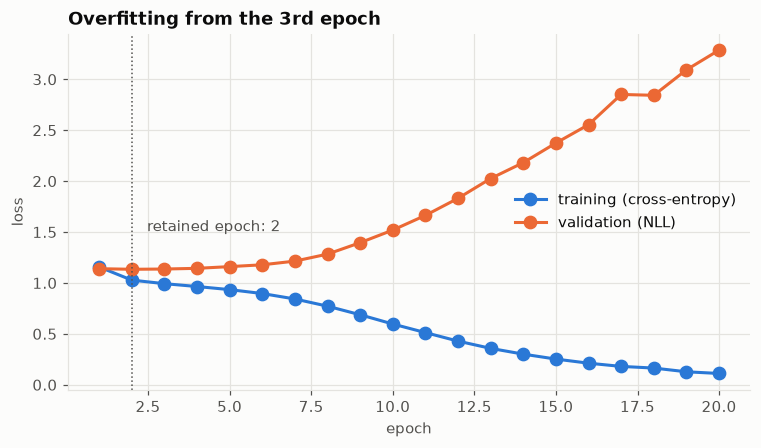

In [5]:
h = pd.DataFrame(mlp.history)
best = h.loc[h.val_nll.idxmin()]
fig, ax = plt.subplots()
ax.plot(h.epoch, h.train_ce, marker="o", label="training (cross-entropy)")
ax.plot(h.epoch, h.val_nll, marker="o", label="validation (NLL)")
ax.axvline(best.epoch, color="#52514e", linestyle=":", linewidth=1)
ax.annotate(f"retained epoch: {int(best.epoch)}", (best.epoch, best.val_nll), xytext=(10, 25),
            textcoords="offset points", color="#52514e")
ax.set_xlabel("epoch"); ax.set_ylabel("loss")
ax.set_title("Overfitting from the 3rd epoch")
ax.legend()
plt.show()

The network memorises the training set from the 3rd epoch onwards. Stronger weight decay or a smaller network does not move the validation ceiling (~0.52): the limit comes from the labels.

In [6]:
strip = lambda m: {k.replace("test_", ""): v for k, v in m.items() if not k.startswith("ood_")}
pd.DataFrame({"always P3 (prior)": naive, "logistic regression": strip(logreg),
              "MLP": strip(mlp.metrics)}).round(3)

,always P3 (prior),logistic regression,MLP
accuracy,0.394,0.459,0.469
macro_f1,0.141,0.400,0.401
nll,1.381,1.289,1.229
brier,0.741,0.687,0.659
ece,0.060,0.096,0.045
spearman_urgency,-0.023,0.292,0.302
p1_recall_top10,0.113,0.237,0.233


## 5. Calibration and errors

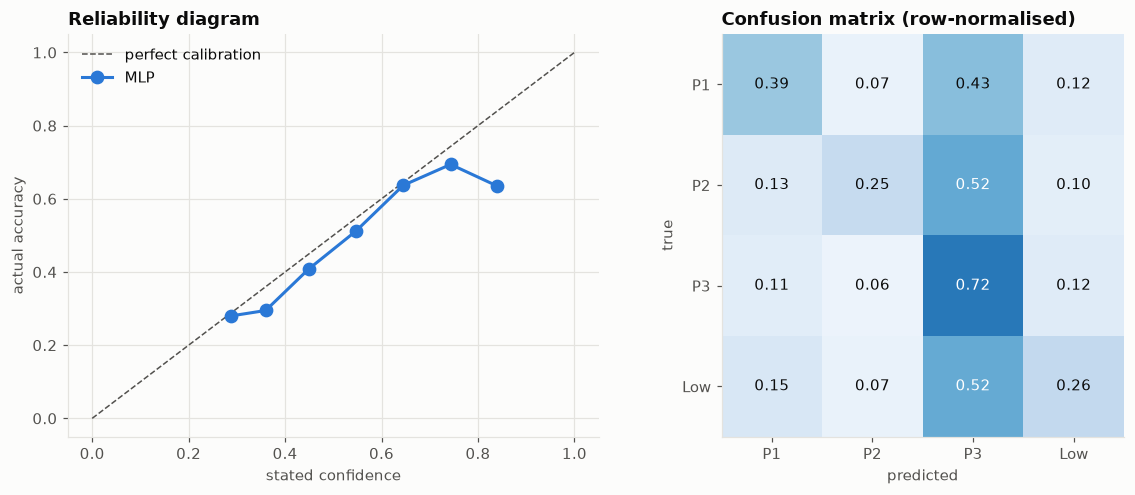

In [7]:
from sklearn.metrics import confusion_matrix
from jem_prioriser.train import predict

p_mlp, _ = predict(mlp.prioriser.model, data.x_test)

def reliability(ax, probs, y, label, color, n_bins=10):
    conf, correct = probs.max(1), (probs.argmax(1) == y)
    idx = np.clip(np.digitize(conf, np.linspace(0, 1, n_bins + 1)) - 1, 0, n_bins - 1)
    keep = [b for b in range(n_bins) if (idx == b).sum() >= 20]
    ax.plot([conf[idx == b].mean() for b in keep], [correct[idx == b].mean() for b in keep],
            marker="o", label=label, color=color)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
axes[0].plot([0, 1], [0, 1], linestyle="--", color="#52514e", linewidth=1, label="perfect calibration")
reliability(axes[0], p_mlp, y_test, "MLP", MODEL_COLORS["MLP"])
axes[0].set_xlabel("stated confidence"); axes[0].set_ylabel("actual accuracy")
axes[0].set_title("Reliability diagram"); axes[0].legend()

cm = confusion_matrix(y_test, p_mlp.argmax(1), normalize="true")
axes[1].imshow(cm, cmap="Blues", vmin=0, vmax=1); axes[1].grid(False)
axes[1].set_xticks(range(4), CLASSES); axes[1].set_yticks(range(4), CLASSES)
axes[1].set_xlabel("predicted"); axes[1].set_ylabel("true")
for i in range(4):
    for j in range(4):
        axes[1].text(j, i, f"{cm[i, j]:.2f}", ha="center", va="center", color="white" if cm[i, j] > 0.5 else "#0b0b0b")
axes[1].set_title("Confusion matrix (row-normalised)")
plt.tight_layout()
plt.show()

- Calibration is good up to ~65% confidence and over-confident beyond it (84% stated for 63% accuracy), on few bugs.
- Errors are dominated by a **fallback to the majority class P3**, which receives 43 to 52% of P1, P2 and Low bugs. Only 39% of P1 and a quarter of P2 and Low bugs are recognised: the predicted class alone is of limited use, hence the continuous **urgency score**, which ranks the queue without forcing a decision.

## 6. Limitation: confidence on unusual bugs

The ~12,500 bot-created bugs, excluded from training, serve as a natural out-of-distribution set.

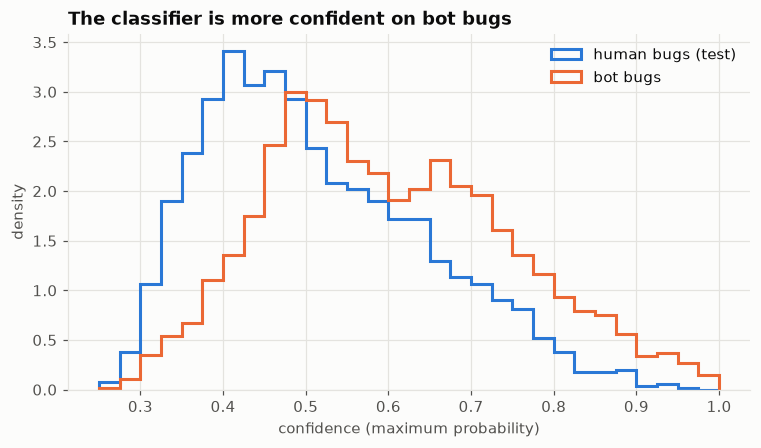

mean confidence: humans 0.51 | bots 0.60
AUROC for detecting bots with 1 - confidence (2026 test): 0.35


In [8]:
p_bots, _ = predict(mlp.prioriser.model, data.x_bots)
fig, ax = plt.subplots()
bins = np.linspace(0.25, 1, 31)
ax.hist(p_mlp.max(1), bins=bins, density=True, histtype="step", linewidth=2, label="human bugs (test)", color=HUMAN_BOT_COLORS["humans"])
ax.hist(p_bots.max(1), bins=bins, density=True, histtype="step", linewidth=2, label="bot bugs", color=HUMAN_BOT_COLORS["bots"])
ax.set_xlabel("confidence (maximum probability)"); ax.set_ylabel("density")
ax.set_title("The classifier is more confident on bot bugs")
ax.legend()
plt.show()
print(f"mean confidence: humans {p_mlp.max(1).mean():.2f} | bots {p_bots.max(1).mean():.2f}")
print(f"AUROC for detecting bots with 1 - confidence (2026 test): {mlp.metrics['ood_auroc_maxprob']:.2f}")

A classifier only learns p(y | x): on stereotyped, unfamiliar texts it extrapolates with **more** confidence. Its confidence cannot be used to flag an atypical bug. This is the starting point of the JEM (notebook 03), which also learns p(x).